In [2]:
from google.colab import files
subidos = files.upload()   # asignamos el resultado para que no se imprima el contenido de los archivos

Saving datos_tomografia_final_128.npz to datos_tomografia_final_128.npz
Saving cargar_datos_tomografia.py to cargar_datos_tomografia.py


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from cargar_datos_tomografia import cargar_datos_tomografia

In [4]:
datos = cargar_datos_tomografia("datos_tomografia_final_128.npz")

A = datos["A"]                       # matriz dispersa (CSR), NO convertir a densa
b = datos["b"]
n = datos["n"]
angulos = datos["angulos"]
posiciones = datos["posiciones_detector"]
norma_ruido = datos["norma_ruido_esperada"]

K = len(angulos)                     # cantidad de ángulos
q = len(posiciones)                  # cantidad de posiciones de detector

print(f"n = {n}, K = {K}, q = {q}")
print("A:", A.shape, "| b:", b.shape)
assert A.shape == (K * q, n**2)
assert b.shape == (K * q,)
print(f"Entradas no nulas de A: {A.nnz:,} ({100 * A.nnz / (A.shape[0] * A.shape[1]):.2f} %)")
print(f"Norma esperada del ruido: {norma_ruido:.2f}")

n = 128, K = 90, q = 183
A: (16470, 16384) | b: (16470,)
Entradas no nulas de A: 1,876,712 (0.70 %)
Norma esperada del ruido: 75.97


La matriz $A$ se carga como matriz dispersa (formato CSR de `scipy.sparse`), que guarda solamente las entradas no nulas. No la convertimos a densa: con $16470 \times 16384$ entradas, ocuparía aproximadamente 2 GB de memoria, cuando solo el 0.7 % de sus entradas son distintas de cero. Esto ocurre porque cada rayo atraviesa únicamente una pequeña fracción de los píxeles de la imagen.

Determinamos $K$ y $q$ como la cantidad de ángulos y de posiciones de detector, respectivamente. Los `assert` verifican que $A \in \mathbb{R}^{Kq \times n^2}$ y $b \in \mathbb{R}^{Kq}$, con $Kq = 90 \times 183 = 16470$ y $n^2 = 128^2 = 16384$.

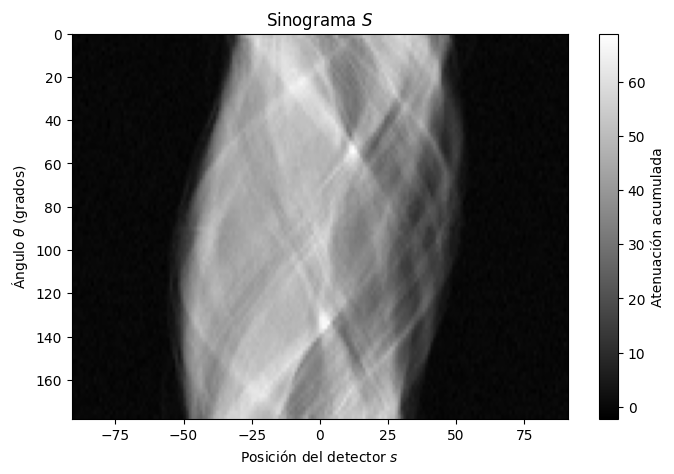

In [5]:
S = b.reshape(K, q)                  # S[k, j] = b[k*q + j]
assert S[5, 17] == b[5 * q + 17]     # chequeo de la regla de indexación

grados = np.degrees(angulos)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(S, cmap="gray", aspect="auto",
               extent=[posiciones[0], posiciones[-1], grados[-1], grados[0]])
ax.set_xlabel("Posición del detector $s$")
ax.set_ylabel(r"Ángulo $\theta$ (grados)")
ax.set_title("Sinograma $S$")
fig.colorbar(im, ax=ax, label="Atenuación acumulada")
plt.show()

Cada fila de $S$ es la proyección del objeto para un ángulo $\theta_k$, y cada columna corresponde a una posición del detector $s_j$. El valor $S_{kj}$ es la atenuación acumulada a lo largo del rayo $\ell_{\theta_k, s_j}$.

**Trazas sinusoidales.** Un punto del objeto con coordenadas $(u, v)$ es atravesado, para cada ángulo $\theta$, por el rayo con
$$s = u\cos\theta + v\sin\theta,$$
que es una función sinusoidal de $\theta$. Por eso cada estructura del objeto aparece en el sinograma como una curva que oscila horizontalmente al variar el ángulo. Las zonas más brillantes donde se cruzan varias trazas corresponden a rayos que atraviesan varias estructuras muy atenuantes a la vez.

**Bordes oscuros.** Para valores de $|s|$ mayores que aproximadamente 50, los rayos no atraviesan el objeto y las mediciones son cercanas a cero. El ancho de la zona clara en cada fila indica el tamaño del objeto visto desde ese ángulo, y su desplazamiento a lo largo de las filas muestra que el objeto no está centrado exactamente en el origen.

**Efecto del ruido.** El valor mínimo de $S$ es aproximadamente $-2.2$. Una atenuación acumulada negativa no tiene sentido físico: corresponde a rayos que no atraviesan el objeto, cuya medición ideal es cero, pero a los que el ruido les agregó una perturbación negativa. Esto confirma que las mediciones contienen ruido, cuya norma esperada informan los datos ($\approx 75.97$), y anticipa la necesidad de regularizar la reconstrucción.

c)

La versión de `matriz_diferencias` del ejercicio 9 construye cada fila como un vector denso de $n^2$ componentes. Para $n = 128$ esto produciría una matriz densa de $32512 \times 16384$, que ocuparía aproximadamente 4.3 GB, aunque cada fila tiene solamente dos entradas no nulas.

La adaptamos para construir $D$ como matriz dispersa. Mantenemos la misma lógica de recorrido de píxeles, pero en lugar de crear filas completas guardamos únicamente tres listas: la fila, la columna y el valor de cada entrada no nula. Los contadores `fila_h` y `fila_v` garantizan que las diferencias horizontales ocupen las primeras $n(n-1)$ filas y las verticales las siguientes, como en la construcción original.

Verificamos que $D \in \mathbb{R}^{2n(n-1) \times n^2}$, que cada fila tiene exactamente un $-1$ y un $1$, que coincide con la versión densa del ejercicio 9 para $n = 8$, y que $D\mathbf{1} = 0$ para una imagen constante.

In [6]:
def matriz_diferencias(n):
    # Inicializamos Dh y Dv
    # Dh tendrá n * (n-1) filas y n^2 columnas
    # Dv tendrá n * (n-1) filas y n^2 columnas
    Dh = []
    Dv = []

    for i in range(n):
        for j in range(n):
            k = i * n + j
            # Diferencia horizontal: X_{i, j+1} - X_{i, j}
            if j < n - 1:                 # Para no desbordar los límites de la imágen (grilla)
                fila_h = np.zeros(n * n)  # Inicializa la fila de cálculo de diferencia horizontal
                fila_h[k] = -1            # X_ij
                fila_h[k + 1] = 1         # X_i, j+1
                Dh.append(fila_h)         # Inserta en Dv

            # Diferencia vertical: X_{i+1, j} - X_{i, j}
            if i < n - 1:                 # Para no desbordar los límites de la imágen (grilla)
                fila_v = np.zeros(n * n)  # Inicializa la fila de cálculo de diferencia vertical
                fila_v[k] = -1            # X_i,j
                fila_v[k + n] = 1         # X_i+1,j
                Dv.append(fila_v)         # Inserta en Dv

    D = np.vstack([Dh, Dv])               # Junta las dos matrices
    return D

In [7]:
def matriz_diferencias_dispersa(n):
    filas, columnas, valores = [], [], []   # solo las entradas no nulas
    fila_h = 0                              # las filas de Dh van de 0 a n(n-1)-1
    fila_v = n * (n - 1)                    # las filas de Dv van a continuación

    for i in range(n):
        for j in range(n):
            k = i * n + j
            # Diferencia horizontal: X_{i,j+1} - X_{i,j}
            if j < n - 1:
                filas += [fila_h, fila_h]
                columnas += [k, k + 1]
                valores += [-1.0, 1.0]
                fila_h += 1
            # Diferencia vertical: X_{i+1,j} - X_{i,j}
            if i < n - 1:
                filas += [fila_v, fila_v]
                columnas += [k, k + n]
                valores += [-1.0, 1.0]
                fila_v += 1

    return sp.csr_matrix((valores, (filas, columnas)), shape=(2 * n * (n - 1), n * n))

In [8]:
D = matriz_diferencias_dispersa(n)

print("D:", D.shape)
assert D.shape == (2 * n * (n - 1), n**2)

nnz_por_fila = D.getnnz(axis=1)
print("Cada fila tiene exactamente 2 no nulos:", np.all(nnz_por_fila == 2))
print("Cada fila tiene un -1 y un 1:", np.allclose(D.sum(axis=1), 0) and np.all(np.abs(D.data) == 1))

# Coincide con la versión densa del ejercicio 9 para una imagen chica
print("Igual a la versión densa (n=8):",
      np.array_equal(matriz_diferencias(8), matriz_diferencias_dispersa(8).toarray()))

# Imagen constante => todas las diferencias son nulas
print("‖D · 1‖ =", np.linalg.norm(D @ np.ones(n**2)))

D: (32512, 16384)
Cada fila tiene exactamente 2 no nulos: True
Cada fila tiene un -1 y un 1: True
Igual a la versión densa (n=8): True
‖D · 1‖ = 0.0


d)

Sin regularización, la reconstrucción minimiza
$$E(x) = \frac{1}{2}\|Ax - b\|^2,$$
con gradiente
$$\nabla E(x) = A^T(Ax - b),$$
igual que en el ejercicio 8, ahora con la matriz de proyección geométrica $A$.

**Elección de la tasa de aprendizaje.** Por el análisis del ejercicio 8, el método converge si $0 < \alpha < 2/\mu_{\max}$, donde $\mu_{\max}$ es el mayor autovalor de la Hessiana $H = A^TA$. Formar $H$ explícitamente no es viable: sería una matriz densa de $16384 \times 16384$. Por eso usamos que los autovalores de $A^TA$ son los cuadrados de los valores singulares de $A$, y calculamos el mayor valor singular con `scipy.sparse.linalg.svds`, que solo requiere productos con $A$. Elegimos $\alpha = 1/\mu_{\max}$, dentro del intervalo de convergencia.

In [9]:
import scipy.sparse.linalg as sla

# Mayor valor singular de A, sin formar A^T A
sigma_A = sla.svds(A, k=1, return_singular_vectors=False)[0]
mu_A = sigma_A**2      # mayor autovalor de A^T A

print(f"μ_máx(AᵀA) = {mu_A:.1f}")

μ_máx(AᵀA) = 11124.1


In [10]:
def gradiente_descendente_reg(A, b, D, lam, alpha, tol=1e-4, max_iter=5000):
    """Minimiza J(x) = 1/2 (‖Ax - b‖² + λ‖Dx‖²) desde x0 = 0.
    Para cuando ‖∇J(x_t)‖ ≤ tol · ‖∇J(x_0)‖ o al llegar a max_iter."""
    x = np.zeros(A.shape[1])
    costos, normas_grad = [], []

    for t in range(max_iter):
        r = A @ x - b                    # residuo
        Dx = D @ x                       # diferencias entre vecinos
        g = A.T @ r + lam * (D.T @ Dx)   # gradiente de J

        costos.append(0.5 * (r @ r + lam * (Dx @ Dx)))
        normas_grad.append(np.linalg.norm(g))

        if normas_grad[-1] <= tol * normas_grad[0]:   # criterio de parada
            break

        x = x - alpha * g

    return x, costos, normas_grad

Iteraciones: 964
‖Ax - b‖ = 45.94   (ruido esperado: 75.97)
Mínimo: -0.268, Máximo: 1.192


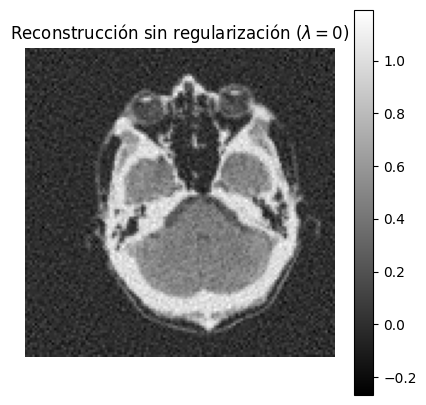

In [11]:
alpha_0 = 1 / mu_A
x_0, costos_0, grads_0 = gradiente_descendente_reg(A, b, D, lam=0, alpha=alpha_0)

print(f"Iteraciones: {len(costos_0)}")
print(f"‖Ax - b‖ = {np.linalg.norm(A @ x_0 - b):.2f}   (ruido esperado: {norma_ruido:.2f})")
print(f"Mínimo: {x_0.min():.3f}, Máximo: {x_0.max():.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(x_0.reshape(n, n), cmap="gray")
ax.set_title(r"Reconstrucción sin regularización ($\lambda = 0$)")
ax.axis("off")
fig.colorbar(im, ax=ax)
plt.show()

**Resultados.** El método se detuvo después de 964 iteraciones. La norma del residuo es $\|Ax - b\| \approx 45.9$, mientras que la norma esperada del ruido es aproximadamente $75.97$.

Que el residuo sea considerablemente menor que la norma del ruido indica que la reconstrucción reproduce las mediciones mejor de lo que permitiría la imagen verdadera: parte de la solución se ajusta al ruido. Esto se observa en la imagen como un granulado que no corresponde a estructuras del objeto.

Además, la reconstrucción toma valores entre $-0.27$ y $1.19$. Como en el ejercicio 6, los valores negativos no tienen sentido físico como coeficientes de atenuación: son consecuencia de resolver mínimos cuadrados sin restricciones sobre datos con ruido.

Por último, con $\lambda = 0$ el resultado depende del criterio de parada: al aumentar las iteraciones, el residuo continúa disminuyendo y la imagen incorpora más ruido. Detener el método antes actúa como una forma de regularización implícita. Esto motiva la incorporación explícita del término $\lambda\|Dx\|^2$.

### e)

Minimizamos
$$J_\lambda(x) = \frac{1}{2}\left(\|Ax - b\|^2 + \lambda\|Dx\|^2\right),$$
cuyo gradiente es
$$\nabla J_\lambda(x) = A^T(Ax - b) + \lambda D^T D x.$$

El primer término mide la fidelidad a las mediciones y el segundo penaliza las diferencias entre píxeles vecinos, favoreciendo imágenes suaves. El parámetro $\lambda$ controla el compromiso entre ambos.

Ahora la Hessiana es $H = A^TA + \lambda D^TD$, y su mayor autovalor crece con $\lambda$. Calculamos $\mu_{\max}(D^TD)$ con `svds`, igual que para $A$. Como $\mu_{\max}(H) \le \mu_{\max}(A^TA) + \lambda\,\mu_{\max}(D^TD)$, elegimos para cada $\lambda$
$$\alpha = \frac{1}{\mu_{\max}(A^TA) + \lambda\,\mu_{\max}(D^TD)},$$
que siempre se encuentra dentro del intervalo de convergencia. Usamos la misma función y el mismo criterio de parada que en el inciso d).

In [12]:
# Mayor autovalor de D^T D, sin formar D^T D
sigma_D = sla.svds(D, k=1, return_singular_vectors=False)[0]
mu_D = sigma_D**2

print(f"μ_máx(DᵀD) = {mu_D:.3f}")

μ_máx(DᵀD) = 7.999


In [13]:
lambdas = [0.1, 1, 10, 30, 40, 100]

# Guardamos también el caso λ = 0 del inciso d) para comparar
resultados = {0: {"x": x_0, "alpha": alpha_0, "iter": len(costos_0),
                  "costos": costos_0, "grads": grads_0}}

for lam in lambdas:
    alpha = 1 / (mu_A + lam * mu_D)
    x_lam, costos, grads = gradiente_descendente_reg(A, b, D, lam=lam, alpha=alpha)
    resultados[lam] = {"x": x_lam, "alpha": alpha, "iter": len(costos),
                       "costos": costos, "grads": grads}
    print(f"λ = {lam:6}: {len(costos):4d} iteraciones, "
          f"‖Ax-b‖ = {np.linalg.norm(A @ x_lam - b):7.2f}")

λ =    0.1:  889 iteraciones, ‖Ax-b‖ =   46.21
λ =      1:  634 iteraciones, ‖Ax-b‖ =   47.61
λ =     10:  369 iteraciones, ‖Ax-b‖ =   56.42
λ =     30:  257 iteraciones, ‖Ax-b‖ =   72.59
λ =     40:  235 iteraciones, ‖Ax-b‖ =   78.80
λ =    100:  185 iteraciones, ‖Ax-b‖ =  103.55


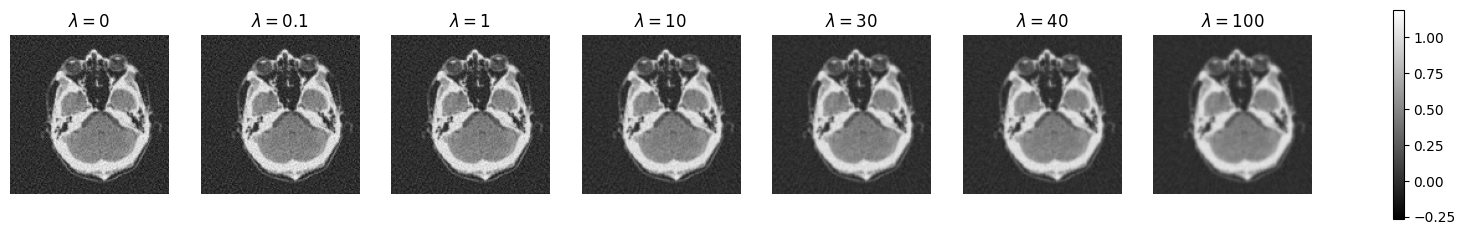

In [14]:
lams = sorted(resultados.keys())
vmin = min(resultados[l]["x"].min() for l in lams)
vmax = max(resultados[l]["x"].max() for l in lams)

fig, axes = plt.subplots(1, len(lams), figsize=(3 * len(lams), 3.4))
for ax, lam in zip(axes, lams):
    im = ax.imshow(resultados[lam]["x"].reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(rf"$\lambda = {lam}$")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

Al aumentar $\lambda$, las reconstrucciones se vuelven más suaves: el granulado presente con $\lambda = 0$ disminuye, pero para valores grandes los bordes entre estructuras también se difuminan. El análisis cuantitativo de este compromiso se presenta en el inciso f).

Además, la cantidad de iteraciones disminuye al aumentar $\lambda$, a pesar de que la tasa de aprendizaje es menor. Esto se debe a que el término $\lambda D^TD$ aumenta la curvatura en las direcciones que $A^TA$ casi no penaliza (las de autovalores pequeños), lo que reduce el número de condición de la Hessiana y acelera la convergencia del gradiente descendente.

### f)

Para cada valor de $\lambda$ registramos la tasa de aprendizaje, la cantidad de iteraciones, la norma del residuo $\|A\hat{x}_\lambda - b\|$, la medida de variación $\|D\hat{x}_\lambda\|$ y los valores mínimo y máximo de la reconstrucción.

La norma del residuo se compara con la norma esperada del ruido incluida en los datos. Si el residuo es mucho menor que el ruido, la reconstrucción está ajustando parte del ruido. Si es mucho mayor, la reconstrucción se aleja de las mediciones más de lo que el ruido justifica, lo que indica una regularización excesiva.

In [15]:
print(f"Norma esperada del ruido: {norma_ruido:.2f}\n")
print(f"{'λ':>6} | {'α':>10} | {'iter':>5} | {'‖Ax-b‖':>8} | {'‖Ax-b‖/ruido':>12} | {'‖Dx‖':>7} | {'mín':>7} | {'máx':>6}")
print("-" * 80)

for lam in lams:
    r = resultados[lam]
    x_lam = r["x"]
    r["residuo"] = np.linalg.norm(A @ x_lam - b)
    r["variacion"] = np.linalg.norm(D @ x_lam)
    print(f"{lam:>6} | {r['alpha']:10.3e} | {r['iter']:5d} | {r['residuo']:8.2f} | "
          f"{r['residuo'] / norma_ruido:12.3f} | {r['variacion']:7.2f} | "
          f"{x_lam.min():7.3f} | {x_lam.max():6.3f}")

Norma esperada del ruido: 75.97

     λ |          α |  iter |   ‖Ax-b‖ | ‖Ax-b‖/ruido |    ‖Dx‖ |     mín |    máx
--------------------------------------------------------------------------------
     0 |  8.990e-05 |   964 |    45.94 |        0.605 |   24.95 |  -0.268 |  1.192
   0.1 |  8.989e-05 |   889 |    46.21 |        0.608 |   24.54 |  -0.259 |  1.186
     1 |  8.983e-05 |   634 |    47.61 |        0.627 |   22.76 |  -0.222 |  1.167
    10 |  8.925e-05 |   369 |    56.42 |        0.743 |   18.25 |  -0.148 |  1.103
    30 |  8.800e-05 |   257 |    72.59 |        0.955 |   14.96 |  -0.104 |  1.072
    40 |  8.738e-05 |   235 |    78.80 |        1.037 |   14.07 |  -0.094 |  1.064
   100 |  8.386e-05 |   185 |   103.55 |        1.363 |   11.39 |  -0.062 |  1.051


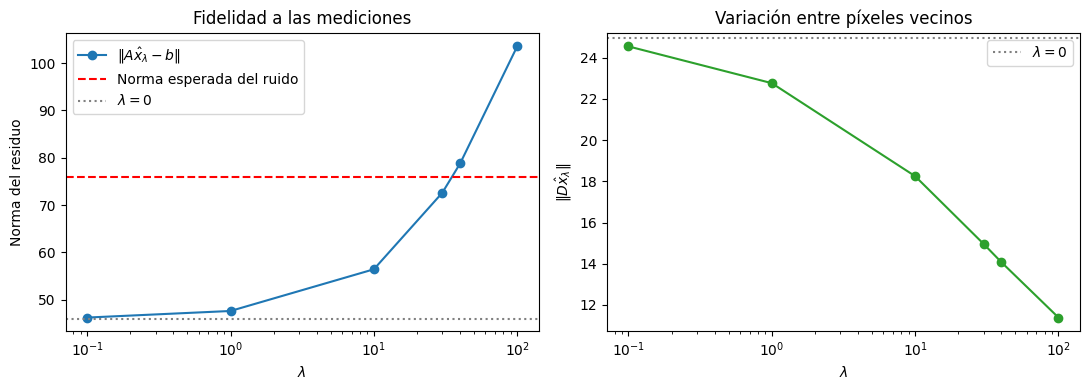

In [16]:
lams_pos = [l for l in lams if l > 0]   # escala log: excluimos λ = 0
residuos = [resultados[l]["residuo"] for l in lams_pos]
variaciones = [resultados[l]["variacion"] for l in lams_pos]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].semilogx(lams_pos, residuos, "o-", label=r"$\|A\hat{x}_\lambda - b\|$")
axes[0].axhline(norma_ruido, color="red", linestyle="--", label="Norma esperada del ruido")
axes[0].axhline(resultados[0]["residuo"], color="gray", linestyle=":", label=r"$\lambda = 0$")
axes[0].set_xlabel(r"$\lambda$")
axes[0].set_ylabel("Norma del residuo")
axes[0].set_title("Fidelidad a las mediciones")
axes[0].legend()

axes[1].semilogx(lams_pos, variaciones, "o-", color="tab:green")
axes[1].axhline(resultados[0]["variacion"], color="gray", linestyle=":", label=r"$\lambda = 0$")
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_ylabel(r"$\|D\hat{x}_\lambda\|$")
axes[1].set_title("Variación entre píxeles vecinos")
axes[1].legend()

plt.tight_layout()
plt.show()

**Análisis.** Al aumentar $\lambda$, la norma del residuo crece y la variación $\|D\hat{x}_\lambda\|$ disminuye: la reconstrucción se vuelve más suave a costa de reproducir peor las mediciones. Este es el compromiso entre fidelidad y suavidad.

Para $\lambda \le 1$, los resultados son prácticamente iguales a los de $\lambda = 0$: el residuo ($\approx 46$–$48$) sigue siendo mucho menor que la norma esperada del ruido ($\approx 75.97$), por lo que estas reconstrucciones todavía ajustan el ruido.

Para $\lambda = 100$, el residuo ($\approx 103.5$) supera ampliamente la norma del ruido: la reconstrucción se aleja de las mediciones más de lo que el ruido justifica, lo que indica un suavizado excesivo.

El residuo coincide aproximadamente con la norma del ruido entre $\lambda = 30$ ($\approx 72.6$) y $\lambda = 40$ ($\approx 78.8$). Una reconstrucción razonable debería diferir de las mediciones aproximadamente en la magnitud del ruido: ni menos (sobreajuste) ni más (suavizado excesivo). Este criterio se conoce como **principio de discrepancia**, y sugiere elegir $\lambda$ en ese rango.

Además, el mínimo de la reconstrucción se acerca a cero al aumentar $\lambda$ (de $-0.27$ a $-0.06$): la regularización reduce las oscilaciones producidas por el ruido, que eran las responsables de los valores negativos sin sentido físico.

g)

In [17]:
# Valor adicional: el residuo cruza la norma del ruido entre λ = 30 y λ = 40
lam = 35
alpha = 1 / (mu_A + lam * mu_D)
x_lam, costos, grads = gradiente_descendente_reg(A, b, D, lam=lam, alpha=alpha)
resultados[lam] = {"x": x_lam, "alpha": alpha, "iter": len(costos), "costos": costos, "grads": grads,
                   "residuo": np.linalg.norm(A @ x_lam - b), "variacion": np.linalg.norm(D @ x_lam)}

print(f"λ = 35: {len(costos)} iteraciones, ‖Ax-b‖ = {resultados[35]['residuo']:.2f}, "
      f"‖Dx‖ = {resultados[35]['variacion']:.2f}   (ruido esperado: {norma_ruido:.2f})")

λ = 35: 245 iteraciones, ‖Ax-b‖ = 75.81, ‖Dx‖ = 14.48   (ruido esperado: 75.97)


Presentamos el sinograma, la reconstrucción sin regularización y tres reconstrucciones regularizadas: una con regularización débil ($\lambda = 10$), la elegida según el principio de discrepancia ($\lambda = 35$) y una con regularización fuerte ($\lambda = 100$). Todas las reconstrucciones usan la misma escala de color.

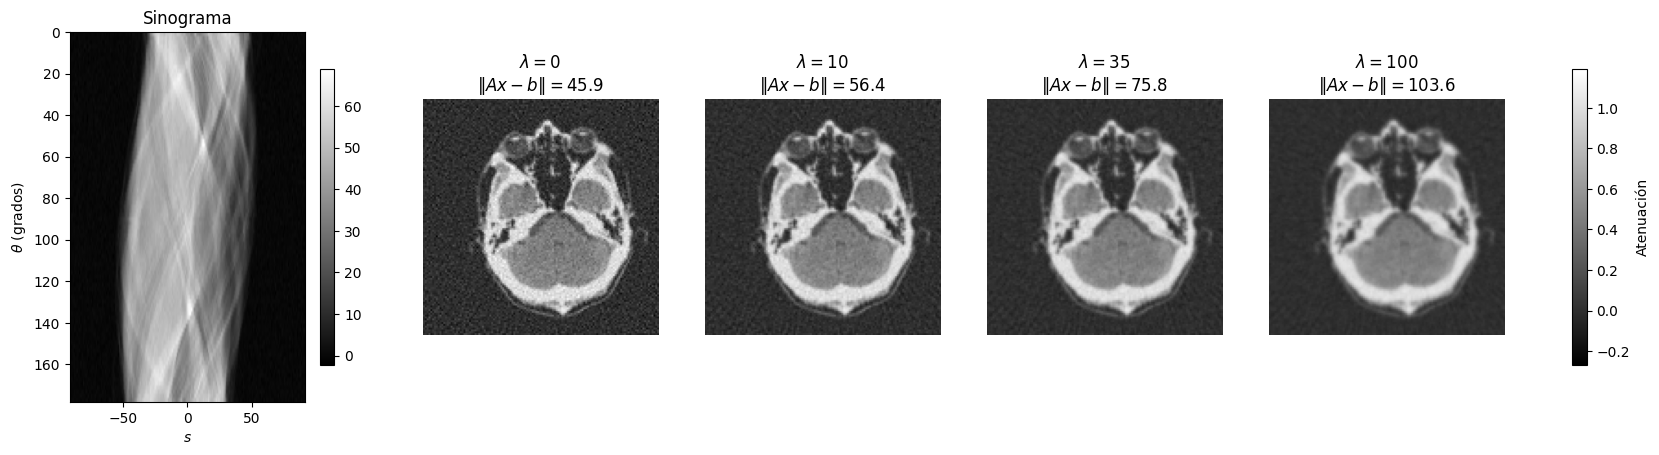

In [18]:
import os
os.makedirs("figuras", exist_ok=True)

lams_fig = [0, 10, 35, 100]
vmin = min(resultados[l]["x"].min() for l in lams_fig)
vmax = max(resultados[l]["x"].max() for l in lams_fig)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))

# Sinograma (escala propia: son mediciones, no atenuaciones por píxel)
im_s = axes[0].imshow(S, cmap="gray", aspect="auto",
                      extent=[posiciones[0], posiciones[-1], grados[-1], grados[0]])
axes[0].set_xlabel("$s$")
axes[0].set_ylabel(r"$\theta$ (grados)")
axes[0].set_title("Sinograma")
fig.colorbar(im_s, ax=axes[0], shrink=0.8)

# Reconstrucciones con escala común
for ax, lam in zip(axes[1:], lams_fig):
    r = resultados[lam]
    im = ax.imshow(r["x"].reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(rf"$\lambda = {lam}$" + "\n" + rf"$\|Ax-b\| = {r['residuo']:.1f}$")
    ax.axis("off")
fig.colorbar(im, ax=axes[1:], shrink=0.8, label="Atenuación")

plt.savefig("figuras/ejercicio_10.png", dpi=150, bbox_inches="tight")
plt.show()

**Elección: $\lambda = 35$.** Justificamos la elección con tres criterios, sin utilizar la imagen original.

*Residuo frente al ruido.* Con $\lambda = 35$, la norma del residuo es $\approx 75.8$, prácticamente igual a la norma esperada del ruido ($\approx 75.97$). Si la reconstrucción fuera la imagen verdadera, el residuo $Ax - b$ sería exactamente el ruido de medición, por lo que su norma debería ser de ese orden. Con $\lambda \le 10$ el residuo es menor que el ruido (la reconstrucción ajusta el ruido), y con $\lambda = 100$ es considerablemente mayor (la reconstrucción se aparta de las mediciones más de lo que el ruido justifica).

*Ruido en la imagen.* Sin regularización, el fondo y las regiones homogéneas presentan un granulado que no corresponde a estructuras del objeto. Con $\lambda = 10$ ese granulado disminuye pero sigue siendo visible. Con $\lambda = 35$, el fondo y las regiones interiores se ven homogéneas.

*Preservación de estructuras.* Con $\lambda = 35$ se distinguen con claridad los contornos principales y los detalles finos del interior. Con $\lambda = 100$, en cambio, los bordes entre regiones se difuminan y se pierden detalles pequeños: la penalización de las diferencias entre vecinos también suaviza los saltos reales de atenuación, no solo el ruido.

Por lo tanto, $\lambda = 35$ ofrece el mejor compromiso entre fidelidad a las mediciones, reducción del ruido y preservación de detalles. La elección no es un óptimo exacto: valores en el rango $30$–$40$ producen reconstrucciones muy similares, y el principio de discrepancia es un criterio razonable, no una garantía de mínimo error respecto de la imagen original.